# Interpolação Polinomial

**Métodos Numéricos — Engenharia Naval (Poli-USP)**

Este notebook é um material de estudo sobre **Interpolação Polinomial**: dado um conjunto de pontos $(x_0,f(x_0)), (x_1,f(x_1)), \dots, (x_n,f(x_n))$, queremos encontrar um polinômio $p(x)$ que passe **exatamente** por todos eles.

Vamos construir, do zero (sem bibliotecas prontas de interpolação), as duas formas clássicas do polinômio interpolador — **Lagrange** e **Newton** — estudar o **erro de truncamento** e encerrar com um dos exemplos mais didáticos de Métodos Numéricos: o **fenômeno de Runge** e como os **nós de Chebyshev** o resolvem.

## Roteiro
1. Formulário (fórmulas oficiais da disciplina)
2. Introdução e motivação
3. Forma de Lagrange
4. Forma de Newton (diferenças divididas)
5. Erro de interpolação e o fenômeno de Runge
6. (Vá além) Distribuição dos nós e estabilidade

## Formulário

Abaixo estão as fórmulas de interpolação polinomial conforme o formulário oficial da disciplina (`formulário.pdf`). Elas serão implementadas e visualizadas ao longo do notebook.

### Polinômios de Lagrange

$$L_i(x) = \frac{(x-x_0)(x-x_1)\cdots(x-x_{i-1})(x-x_{i+1})\cdots(x-x_n)}{(x_i-x_0)(x_i-x_1)\cdots(x_i-x_{i-1})(x_i-x_{i+1})\cdots(x_i-x_n)}$$

### Polinômio interpolador na forma de Lagrange

$$p(x) = f(x_0)L_0(x) + f(x_1)L_1(x) + \cdots + f(x_n)L_n(x)$$

### Polinômio interpolador na forma de Newton (diferenças divididas)

$$p(x) = f[x_0] + (x-x_0)f[x_0,x_1] + \cdots + (x-x_0)(x-x_1)\cdots(x-x_{n-1})f[x_0,x_1,\dots,x_n]$$

ou, com nós igualmente espaçados (diferenças finitas), ainda:

$$p(x) = f(x_0) + (x-x_0)\frac{\Delta f(x_0)}{h} + \cdots + (x-x_0)(x-x_1)\cdots(x-x_{n-1})\frac{\Delta^n f(x_0)}{n!\,h^n}$$

### Erro de truncamento na interpolação polinomial

$$E_n(x) = (x-x_0)(x-x_1)\cdots(x-x_n)\,\frac{f^{(n+1)}(\sigma)}{(n+1)!}, \qquad \sigma \in I$$

onde $I$ é o menor intervalo que contém $x_0, x_1, \dots, x_n$ e $x$.

In [1]:
# Bibliotecas usadas no notebook inteiro
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

# Configurações visuais padrão para deixar os gráficos consistentes
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

# Paleta de cores fixa para reutilizar nos gráficos (pontos, nós, curvas)
COR_FUNCAO = 'black'
COR_PONTOS = 'crimson'
COR_POLINOMIO = 'royalblue'
COR_NEWTON = 'darkorange'

## 1. Introdução e motivação

**O problema da interpolação.** Em engenharia, frequentemente conhecemos o valor de uma grandeza apenas em alguns pontos discretos — por exemplo, a resistência ao avanço de um casco medida em um tanque de provas para algumas velocidades, ou propriedades de um fluido tabeladas para certas temperaturas. Quando precisamos estimar o valor em um ponto **entre** os pontos conhecidos, recorremos à **interpolação**: encontrar uma função simples (tipicamente um polinômio) que passe **exatamente** por todos os pontos dados, e usá-la para estimar valores intermediários.

**Interpolação × ajuste por mínimos quadrados.** É importante não confundir os dois problemas:

- **Interpolação:** os dados são considerados **exatos** (sem ruído/erro de medição) e exigimos que $p(x_i) = f(x_i)$ para **todos** os pontos, exatamente. É o problema que estudamos aqui.
- **Ajuste por mínimos quadrados:** os dados são **ruidosos** (ex.: medições experimentais com erro aleatório) e **não** exigimos que a curva passe exatamente pelos pontos — em vez disso, buscamos a curva que **minimiza o erro quadrático total**, suavizando o ruído.

**Unicidade do polinômio interpolador.** Um resultado fundamental: dados $n+1$ pontos com abscissas **distintas** $x_0, x_1, \dots, x_n$, existe **um único** polinômio $p(x)$ de grau **menor ou igual a $n$** que passa por todos eles. Isso significa que, não importa qual método usarmos para construí-lo (Lagrange, Newton, ou resolvendo o sistema linear de Vandermonde diretamente), o polinômio resultante é sempre **o mesmo** — apenas a forma de calculá-lo muda. Vamos comprovar isso na prática comparando Lagrange e Newton mais adiante.

## 2. Forma de Lagrange

A ideia da forma de Lagrange é construir, para cada nó $x_i$, um polinômio-base $L_i(x)$ com a propriedade:

$$L_i(x_j) = \begin{cases} 1, & j = i \\ 0, & j \neq i \end{cases}$$

Ou seja, $L_i(x)$ vale $1$ exatamente no nó $x_i$ e se anula em **todos os outros nós**. Com essa propriedade, a combinação

$$p(x) = \sum_{i=0}^{n} f(x_i)\,L_i(x)$$

automaticamente satisfaz $p(x_j) = f(x_j)$ para todo $j$, pois no ponto $x_j$ apenas o termo $i=j$ "sobrevive" (todos os outros se anulam).

Vamos implementar $L_i(x)$ e $p(x)$ do zero e visualizar essa propriedade.

In [2]:
def base_lagrange(x_nos, i, x):
    """Calcula o polinômio-base L_i(x) de Lagrange, avaliado no array x.

    x_nos: array com as abscissas dos nós (x_0, ..., x_n)
    i: índice do nó para o qual queremos construir L_i
    x: ponto (ou array de pontos) onde L_i será avaliado
    """
    x = np.asarray(x, dtype=float)
    xi = x_nos[i]
    resultado = np.ones_like(x)
    for j, xj in enumerate(x_nos):
        if j != i:
            # Multiplica por (x - x_j) / (x_i - x_j) para cada j != i
            resultado = resultado * (x - xj) / (xi - xj)
    return resultado


def polinomio_lagrange(x_nos, y_nos, x):
    """Avalia o polinômio interpolador p(x) na forma de Lagrange.

    p(x) = soma_i f(x_i) * L_i(x)
    """
    x = np.asarray(x, dtype=float)
    p = np.zeros_like(x)
    for i in range(len(x_nos)):
        p = p + y_nos[i] * base_lagrange(x_nos, i, x)
    return p

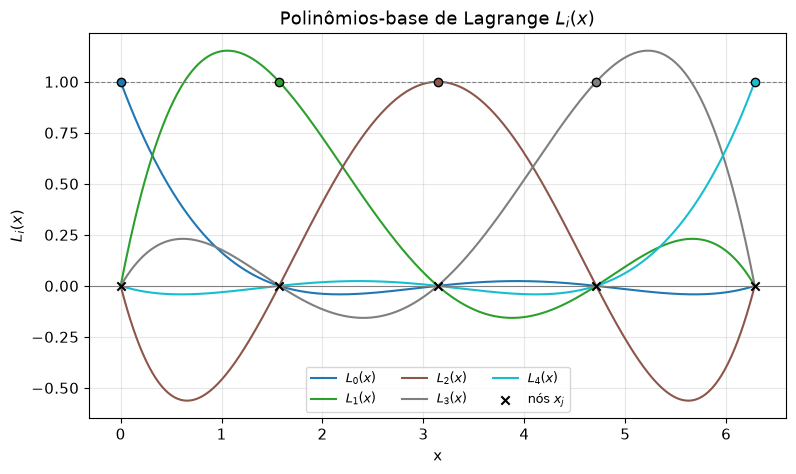

Matriz L_i(x_j) (deveria ser a identidade):
[[ 1. -0.  0. -0.  0.]
 [ 0.  1. -0.  0. -0.]
 [-0.  0.  1. -0.  0.]
 [ 0. -0.  0.  1. -0.]
 [-0.  0. -0.  0.  1.]]


In [3]:
# Vamos usar 5 pontos retirados de f(x) = sin(x) no intervalo [0, 2*pi]
n_pontos = 5
x_nos = np.linspace(0, 2 * np.pi, n_pontos)
y_nos = np.sin(x_nos)

x_plot = np.linspace(0, 2 * np.pi, 400)

# Cada L_i(x) é plotada em uma cor diferente
cores = plt.cm.tab10(np.linspace(0, 1, n_pontos))

plt.figure()
for i in range(n_pontos):
    Li = base_lagrange(x_nos, i, x_plot)
    plt.plot(x_plot, Li, color=cores[i], label=f'$L_{i}(x)$')
    # Marca o próprio nó x_i, onde L_i deve valer exatamente 1
    plt.scatter([x_nos[i]], [1.0], color=cores[i], zorder=5, edgecolor='black')

# Marca todos os nós no eixo x para reforçar onde cada L_i se anula
plt.scatter(x_nos, np.zeros(n_pontos), color='black', marker='x', zorder=5, label='nós $x_j$')
plt.axhline(0, color='gray', linewidth=0.8)
plt.axhline(1, color='gray', linewidth=0.8, linestyle='--')
plt.title('Polinômios-base de Lagrange $L_i(x)$')
plt.xlabel('x')
plt.ylabel('$L_i(x)$')
plt.legend(ncol=3, fontsize=9)
plt.show()

# Confere numericamente a propriedade L_i(x_j) = delta_ij
print('Matriz L_i(x_j) (deveria ser a identidade):')
matriz_check = np.array([[base_lagrange(x_nos, i, x_nos[j]) for j in range(n_pontos)] for i in range(n_pontos)])
print(np.round(matriz_check, 10))

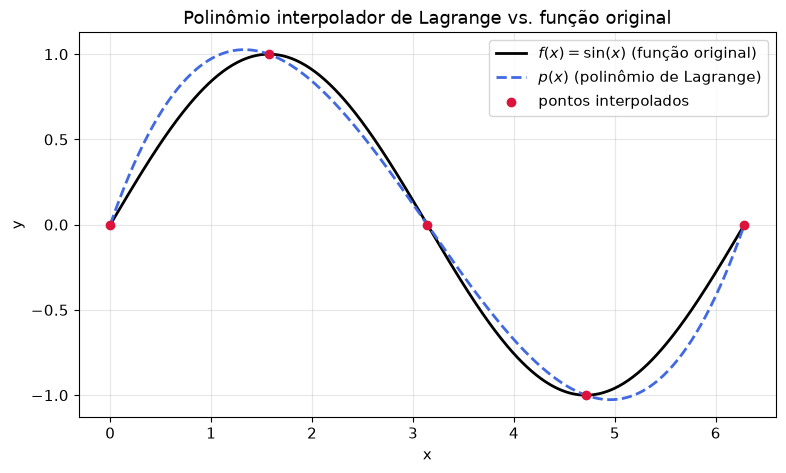

In [4]:
# Agora montamos p(x) = soma f(x_i) * L_i(x) e comparamos com f(x) = sin(x)
p_lagrange = polinomio_lagrange(x_nos, y_nos, x_plot)

plt.figure()
plt.plot(x_plot, np.sin(x_plot), color=COR_FUNCAO, linewidth=2, label='$f(x) = \\sin(x)$ (função original)')
plt.plot(x_plot, p_lagrange, color=COR_POLINOMIO, linestyle='--', linewidth=2, label='$p(x)$ (polinômio de Lagrange)')
plt.scatter(x_nos, y_nos, color=COR_PONTOS, zorder=5, label='pontos interpolados')
plt.title('Polinômio interpolador de Lagrange vs. função original')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 3. Forma de Newton (diferenças divididas)

A forma de Lagrange tem uma desvantagem prática: se quisermos **adicionar um novo ponto** à interpolação, é preciso recalcular **todos** os $L_i(x)$ do zero, pois cada um depende de todos os nós.

A forma de Newton resolve isso construindo o polinômio **incrementalmente**:

$$p(x) = f[x_0] + (x-x_0)f[x_0,x_1] + (x-x_0)(x-x_1)f[x_0,x_1,x_2] + \cdots$$

onde $f[x_0,x_1,\dots,x_k]$ são as **diferenças divididas**, calculadas recursivamente:

$$f[x_i] = f(x_i), \qquad f[x_i, x_{i+1}, \dots, x_{i+k}] = \frac{f[x_{i+1},\dots,x_{i+k}] - f[x_i,\dots,x_{i+k-1}]}{x_{i+k}-x_i}$$

Essas diferenças são organizadas em uma **tabela triangular** (o "triângulo de diferenças divididas"), onde cada coluna usa apenas os valores da coluna anterior. Os coeficientes do polinômio de Newton são simplesmente a **primeira linha** dessa tabela: $f[x_0], f[x_0,x_1], f[x_0,x_1,x_2], \dots$

Pela **unicidade do polinômio interpolador** (Seção 1), o resultado deve ser **idêntico** ao obtido por Lagrange — vamos comprovar isso.

In [5]:
def tabela_diferencas_divididas(x_nos, y_nos):
    """Monta a tabela triangular de diferenças divididas.

    tabela[i, j] = f[x_i, x_{i+1}, ..., x_{i+j}]
    A primeira coluna (j=0) é simplesmente y_nos.
    """
    n = len(x_nos)
    tabela = np.zeros((n, n))
    tabela[:, 0] = y_nos
    for j in range(1, n):
        for i in range(n - j):
            tabela[i, j] = (tabela[i + 1, j - 1] - tabela[i, j - 1]) / (x_nos[i + j] - x_nos[i])
    return tabela


def polinomio_newton(x_nos, coefs, x):
    """Avalia o polinômio de Newton dados os nós e os coeficientes (primeira linha da tabela).

    p(x) = coefs[0] + coefs[1]*(x-x0) + coefs[2]*(x-x0)(x-x1) + ...
    """
    x = np.asarray(x, dtype=float)
    n = len(coefs)
    p = np.full_like(x, coefs[0])
    termo = np.ones_like(x)  # produto acumulado (x-x0)(x-x1)...
    for k in range(1, n):
        termo = termo * (x - x_nos[k - 1])
        p = p + coefs[k] * termo
    return p


# Monta a tabela para os mesmos pontos de sin(x) usados na seção de Lagrange
tabela = tabela_diferencas_divididas(x_nos, y_nos)
coefs_newton = tabela[0, :]  # f[x0], f[x0,x1], f[x0,x1,x2], ...

print('Tabela de diferenças divididas (cada coluna j usa a coluna j-1):')
print(np.round(tabela, 4))
print('\nCoeficientes de Newton (primeira linha):', np.round(coefs_newton, 4))

Tabela de diferenças divididas (cada coluna j usa a coluna j-1):
[[ 0.      0.6366 -0.4053  0.086   0.    ]
 [ 1.     -0.6366 -0.      0.086   0.    ]
 [ 0.     -0.6366  0.4053  0.      0.    ]
 [-1.      0.6366  0.      0.      0.    ]
 [-0.      0.      0.      0.      0.    ]]

Coeficientes de Newton (primeira linha): [ 0.      0.6366 -0.4053  0.086   0.    ]


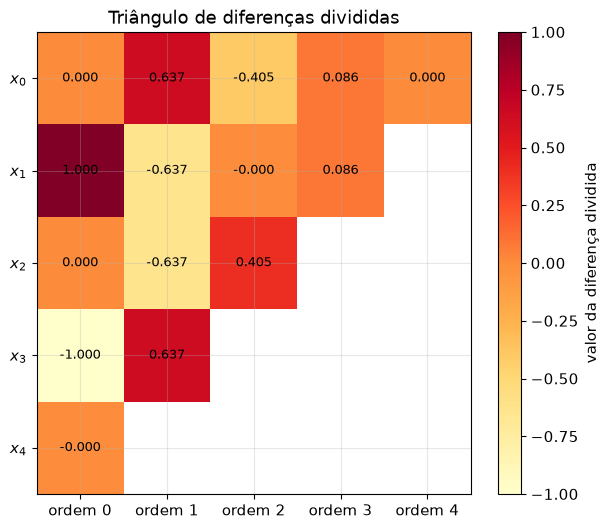

In [6]:
# Visualização da tabela de diferenças divididas como um heatmap triangular,
# para reforçar visualmente que cada coluna "come" uma linha da anterior.
n = len(x_nos)
# Máscara: na linha i, só as colunas j <= n-1-i correspondem a diferenças válidas
valido = np.array([[j <= n - 1 - i for j in range(n)] for i in range(n)])
tabela_mascarada = np.where(valido, tabela, np.nan)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(tabela_mascarada, cmap='YlOrRd', aspect='auto')
for i in range(n):
    for j in range(n - i):
        ax.text(j, i, f'{tabela[i, j]:.3f}', ha='center', va='center', fontsize=9)
ax.set_xticks(range(n))
ax.set_xticklabels([f'ordem {j}' for j in range(n)])
ax.set_yticks(range(n))
ax.set_yticklabels([f'$x_{i}$' for i in range(n)])
ax.set_title('Triângulo de diferenças divididas')
fig.colorbar(im, ax=ax, label='valor da diferença dividida')
plt.show()

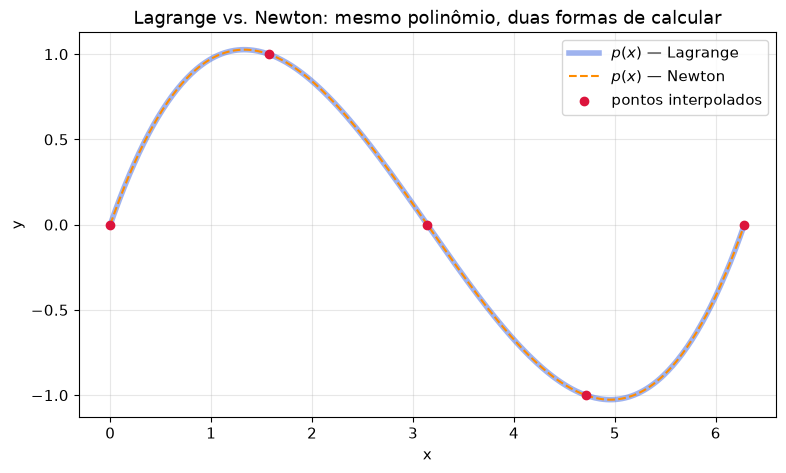

Maior diferença absoluta entre as duas curvas: 2.05e-15 (deve ser ~0, a menos de erro numérico)


In [7]:
# Comparação: Lagrange x Newton devem dar EXATAMENTE a mesma curva
p_newton = polinomio_newton(x_nos, coefs_newton, x_plot)

plt.figure()
plt.plot(x_plot, p_lagrange, color=COR_POLINOMIO, linewidth=4, alpha=0.5, label='$p(x)$ — Lagrange')
plt.plot(x_plot, p_newton, color=COR_NEWTON, linewidth=1.5, linestyle='--', label='$p(x)$ — Newton')
plt.scatter(x_nos, y_nos, color=COR_PONTOS, zorder=5, label='pontos interpolados')
plt.title('Lagrange vs. Newton: mesmo polinômio, duas formas de calcular')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

diferenca_maxima = np.max(np.abs(p_lagrange - p_newton))
print(f'Maior diferença absoluta entre as duas curvas: {diferenca_maxima:.2e} (deve ser ~0, a menos de erro numérico)')

### Vantagem prática de Newton: adicionar pontos sem recomeçar

Na forma de Newton, cada novo ponto adicionado contribui com **um termo a mais**, somado ao polinômio que já tínhamos — não é preciso recalcular nada do que já foi feito. Na forma de Lagrange, ao contrário, adicionar um ponto muda **todos** os $L_i(x)$, pois cada um depende do conjunto completo de nós.

Abaixo, construímos o polinômio de Newton **incrementalmente**: começamos com apenas 1 ponto (uma constante), depois acrescentamos pontos um a um, mostrando como cada novo termo refina a aproximação anterior.

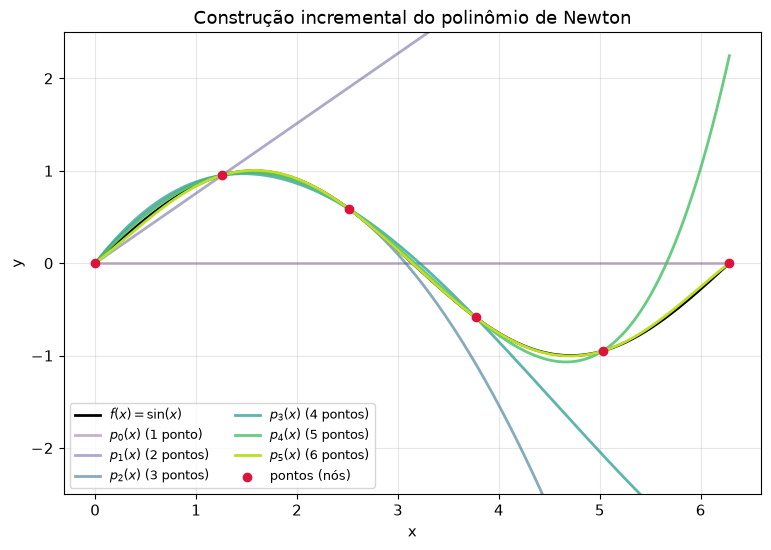

In [8]:
# Usamos mais pontos de sin(x) para deixar o efeito incremental mais visível
n_incremental = 6
x_inc = np.linspace(0, 2 * np.pi, n_incremental)
y_inc = np.sin(x_inc)
tabela_inc = tabela_diferencas_divididas(x_inc, y_inc)
coefs_inc = tabela_inc[0, :]

plt.figure(figsize=(9, 6))
plt.plot(x_plot, np.sin(x_plot), color=COR_FUNCAO, linewidth=2, label='$f(x) = \\sin(x)$')

# Transparência crescente: polinômios com mais pontos ficam mais opacos (mais "definitivos")
alphas = np.linspace(0.3, 1.0, n_incremental)
cores_inc = plt.cm.viridis(np.linspace(0, 0.9, n_incremental))

for k in range(1, n_incremental + 1):
    # Usa apenas os k primeiros nós e os k primeiros coeficientes: p_k(x)
    p_k = polinomio_newton(x_inc[:k], coefs_inc[:k], x_plot)
    plt.plot(x_plot, p_k, color=cores_inc[k - 1], alpha=alphas[k - 1], linewidth=2,
             label=f'$p_{k-1}(x)$ ({k} ponto{"s" if k > 1 else ""})')

plt.scatter(x_inc, y_inc, color=COR_PONTOS, zorder=5, label='pontos (nós)')
plt.title('Construção incremental do polinômio de Newton')
plt.xlabel('x')
plt.ylabel('y')
plt.ylim(-2.5, 2.5)
plt.legend(ncol=2, fontsize=9)
plt.show()

## 4. Erro de interpolação e o fenômeno de Runge

Como o polinômio interpolador $p(x)$ coincide com $f(x)$ apenas nos nós, em qualquer outro ponto existe um **erro de truncamento**:

$$E_n(x) = f(x) - p(x) = (x-x_0)(x-x_1)\cdots(x-x_n)\,\frac{f^{(n+1)}(\sigma)}{(n+1)!}, \qquad \sigma \in I$$

Essa fórmula mostra dois fatores que controlam o erro:

1. O **produto** $(x-x_0)(x-x_1)\cdots(x-x_n)$: cresce quando $x$ está longe dos nós, e depende de **onde** os nós estão colocados.
2. A **derivada de ordem $n+1$** de $f$: se $f$ oscila muito ou cresce rapidamente, essa derivada pode ser grande.

Como $\sigma$ não é conhecido exatamente, na prática usamos um **limitante**: $M_{n+1} = \max_{x \in I} |f^{(n+1)}(x)|$, o que dá uma **cota superior** para o erro.

Vamos testar isso com $f(x) = e^x$ (cuja derivada de qualquer ordem é a própria $e^x$, fácil de calcular exatamente).

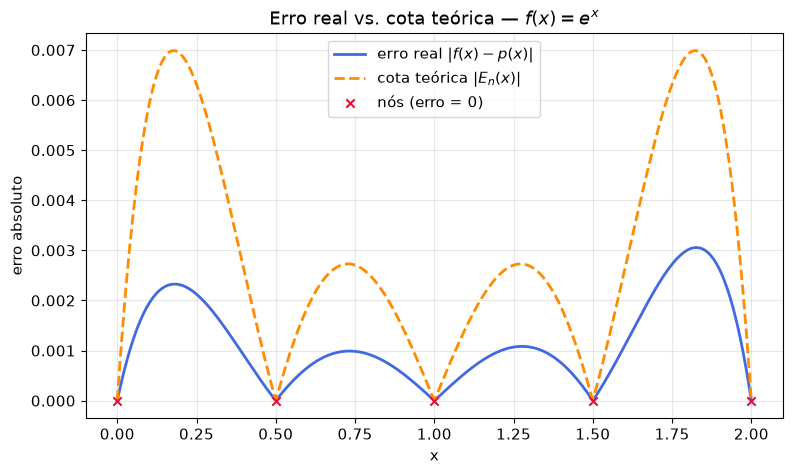

In [9]:
def cota_erro_teorico(x, x_nos, M_n1, n):
    """Cota superior para |E_n(x)|, usando M_n1 = max|f^(n+1)| no intervalo.

    |E_n(x)| <= |produto (x - x_i)| * M_n1 / (n+1)!
    """
    x = np.asarray(x, dtype=float)
    produto = np.ones_like(x)
    for xi in x_nos:
        produto = produto * (x - xi)
    return np.abs(produto) * M_n1 / factorial(n + 1)


# f(x) = e^x em [0, 2], interpolada com n+1 = 5 pontos (n = 4)
f_exp = np.exp
x_nos_exp = np.linspace(0, 2, 5)
y_nos_exp = f_exp(x_nos_exp)
n_exp = len(x_nos_exp) - 1
x_plot_exp = np.linspace(0, 2, 400)

tabela_exp = tabela_diferencas_divididas(x_nos_exp, y_nos_exp)
p_exp = polinomio_newton(x_nos_exp, tabela_exp[0, :], x_plot_exp)

# Como f^(n+1)(x) = e^x é crescente, o máximo no intervalo [0,2] ocorre em x=2
M_n1 = f_exp(2)
erro_real = np.abs(f_exp(x_plot_exp) - p_exp)
erro_teorico = cota_erro_teorico(x_plot_exp, x_nos_exp, M_n1, n_exp)

plt.figure()
plt.plot(x_plot_exp, erro_real, color=COR_POLINOMIO, linewidth=2, label='erro real $|f(x) - p(x)|$')
plt.plot(x_plot_exp, erro_teorico, color=COR_NEWTON, linestyle='--', linewidth=2, label='cota teórica $|E_n(x)|$')
plt.scatter(x_nos_exp, np.zeros_like(x_nos_exp), color=COR_PONTOS, marker='x', zorder=5, label='nós (erro = 0)')
plt.title('Erro real vs. cota teórica — $f(x) = e^x$')
plt.xlabel('x')
plt.ylabel('erro absoluto')
plt.legend()
plt.show()

### O fenômeno de Runge

Seria natural pensar que, quanto **mais pontos** (maior grau $n$) usarmos, **melhor** será a aproximação. Isso é **falso em geral** quando os nós são **igualmente espaçados**!

O exemplo clássico é a **função de Runge**:

$$f(x) = \frac{1}{1+25x^2}, \qquad x \in [-1, 1]$$

Ela é perfeitamente suave (infinitamente derivável), mas ao interpolá-la com nós igualmente espaçados e aumentar o grau do polinômio, o erro **não diminui** — pelo contrário, **surgem oscilações cada vez maiores perto das extremidades** do intervalo. Esse comportamento é conhecido como **fenômeno de Runge**.

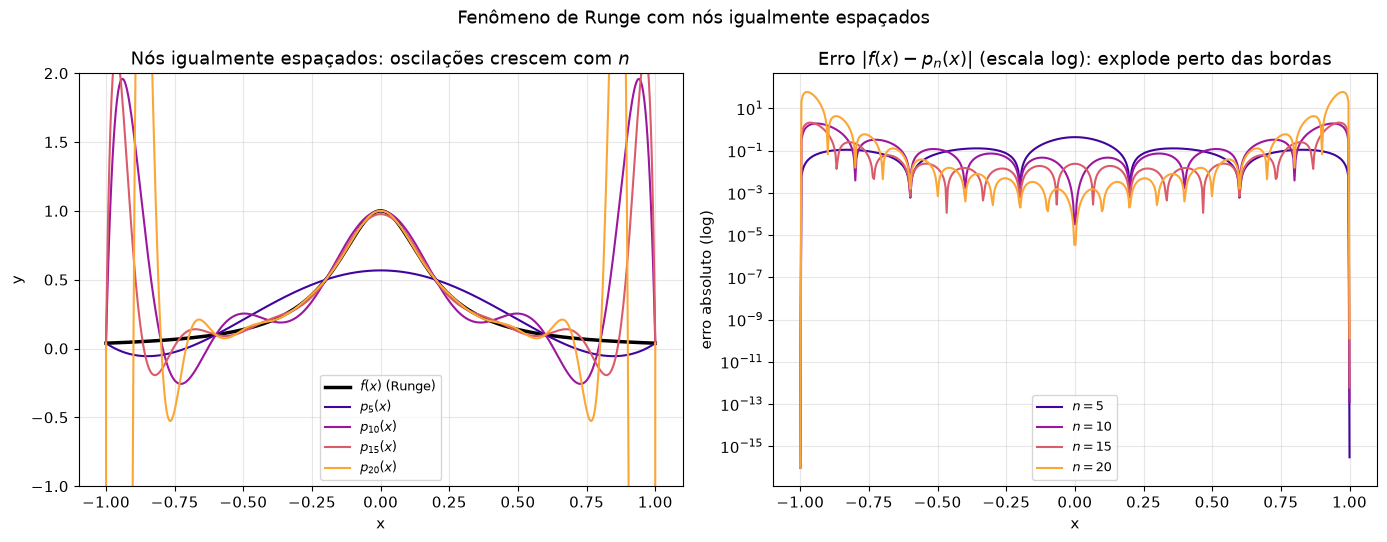

In [10]:
def f_runge(x):
    """Função de Runge: f(x) = 1 / (1 + 25*x^2)"""
    return 1.0 / (1.0 + 25.0 * x ** 2)


x_plot_runge = np.linspace(-1, 1, 500)
graus = [5, 10, 15, 20]
cores_graus = plt.cm.plasma(np.linspace(0.1, 0.8, len(graus)))

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Painel esquerdo: p_n(x) vs f(x) para nós igualmente espaçados ---
axs[0].plot(x_plot_runge, f_runge(x_plot_runge), color=COR_FUNCAO, linewidth=2.5, label='$f(x)$ (Runge)')
for grau, cor in zip(graus, cores_graus):
    x_eq = np.linspace(-1, 1, grau + 1)  # nós igualmente espaçados
    y_eq = f_runge(x_eq)
    tab = tabela_diferencas_divididas(x_eq, y_eq)
    p_eq = polinomio_newton(x_eq, tab[0, :], x_plot_runge)
    axs[0].plot(x_plot_runge, p_eq, color=cor, linewidth=1.5, label=f'$p_{{{grau}}}(x)$')
axs[0].set_title('Nós igualmente espaçados: oscilações crescem com $n$')
axs[0].set_xlabel('x')
axs[0].set_ylabel('y')
axs[0].set_ylim(-1, 2)
axs[0].legend(fontsize=9)

# --- Painel direito: erro |f(x) - p_n(x)| em escala log, mostrando a explosão nas bordas ---
for grau, cor in zip(graus, cores_graus):
    x_eq = np.linspace(-1, 1, grau + 1)
    y_eq = f_runge(x_eq)
    tab = tabela_diferencas_divididas(x_eq, y_eq)
    p_eq = polinomio_newton(x_eq, tab[0, :], x_plot_runge)
    erro = np.abs(f_runge(x_plot_runge) - p_eq)
    axs[1].semilogy(x_plot_runge, erro + 1e-16, color=cor, linewidth=1.5, label=f'$n={grau}$')
axs[1].set_title('Erro $|f(x)-p_n(x)|$ (escala log): explode perto das bordas')
axs[1].set_xlabel('x')
axs[1].set_ylabel('erro absoluto (log)')
axs[1].legend(fontsize=9)

plt.suptitle('Fenômeno de Runge com nós igualmente espaçados', fontsize=13)
plt.tight_layout()
plt.show()

### A solução: nós de Chebyshev

O problema não é a interpolação polinomial em si, mas a **escolha dos nós**. Em vez de espaçá-los uniformemente, podemos concentrar mais nós **perto das extremidades** do intervalo, onde o produto $(x-x_0)(x-x_1)\cdots(x-x_n)$ do erro tende a ser maior. Os **nós de Chebyshev** fazem exatamente isso:

$$x_k = \cos\!\left(\frac{(2k+1)\pi}{2(n+1)}\right), \qquad k = 0, 1, \dots, n \quad (\text{nós em } [-1,1])$$

Repetindo o mesmo experimento com nós de Chebyshev, o erro passa a **diminuir** conforme aumentamos o grau — o fenômeno de Runge desaparece.

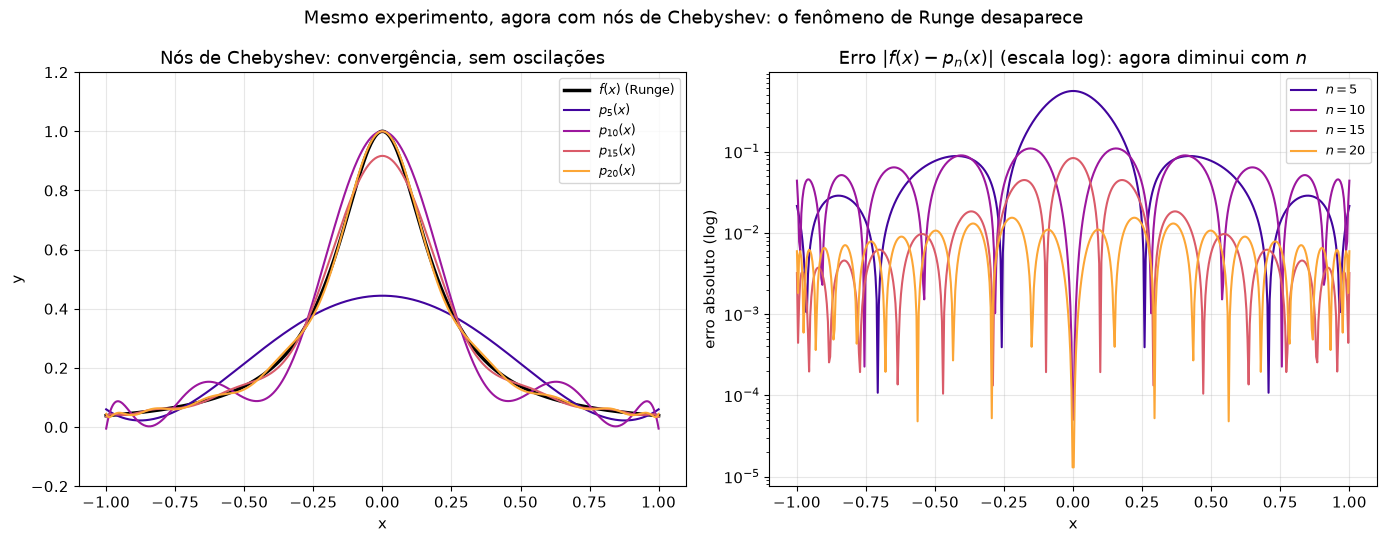

In [11]:
def nos_chebyshev(n):
    """Gera os n+1 nós de Chebyshev no intervalo [-1, 1]."""
    k = np.arange(n + 1)
    return np.cos((2 * k + 1) * np.pi / (2 * (n + 1)))


fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Painel esquerdo: p_n(x) vs f(x) com nós de Chebyshev ---
axs[0].plot(x_plot_runge, f_runge(x_plot_runge), color=COR_FUNCAO, linewidth=2.5, label='$f(x)$ (Runge)')
for grau, cor in zip(graus, cores_graus):
    x_cheb = np.sort(nos_chebyshev(grau))  # ordena para a tabela de diferenças divididas
    y_cheb = f_runge(x_cheb)
    tab = tabela_diferencas_divididas(x_cheb, y_cheb)
    p_cheb = polinomio_newton(x_cheb, tab[0, :], x_plot_runge)
    axs[0].plot(x_plot_runge, p_cheb, color=cor, linewidth=1.5, label=f'$p_{{{grau}}}(x)$')
axs[0].set_title('Nós de Chebyshev: convergência, sem oscilações')
axs[0].set_xlabel('x')
axs[0].set_ylabel('y')
axs[0].set_ylim(-0.2, 1.2)
axs[0].legend(fontsize=9)

# --- Painel direito: erro em escala log, agora decrescente com n ---
for grau, cor in zip(graus, cores_graus):
    x_cheb = np.sort(nos_chebyshev(grau))
    y_cheb = f_runge(x_cheb)
    tab = tabela_diferencas_divididas(x_cheb, y_cheb)
    p_cheb = polinomio_newton(x_cheb, tab[0, :], x_plot_runge)
    erro = np.abs(f_runge(x_plot_runge) - p_cheb)
    axs[1].semilogy(x_plot_runge, erro + 1e-16, color=cor, linewidth=1.5, label=f'$n={grau}$')
axs[1].set_title('Erro $|f(x)-p_n(x)|$ (escala log): agora diminui com $n$')
axs[1].set_xlabel('x')
axs[1].set_ylabel('erro absoluto (log)')
axs[1].legend(fontsize=9)

plt.suptitle('Mesmo experimento, agora com nós de Chebyshev: o fenômeno de Runge desaparece', fontsize=13)
plt.tight_layout()
plt.show()

## 5. Vá além: como a escolha dos nós afeta a estabilidade

Para entender **por que** os nós de Chebyshev funcionam melhor, vale visualizar diretamente **onde** cada conjunto de nós coloca seus pontos. A ideia central: nós igualmente espaçados distribuem os pontos de forma uniforme, enquanto os nós de Chebyshev se **concentram perto das extremidades** do intervalo (e ficam mais esparsos no centro) — justamente onde o produto $(x-x_0)\cdots(x-x_n)$ do erro é maior.

Uma forma rigorosa de medir isso é pela **função de Lebesgue**:

$$\Lambda_n(x) = \sum_{i=0}^{n} |L_i(x)|$$

Quanto maior o pico de $\Lambda_n(x)$, mais instável é a interpolação (pequenos erros nos dados são amplificados). Nós igualmente espaçados têm $\Lambda_n$ crescendo **exponencialmente** com $n$; nós de Chebyshev mantêm $\Lambda_n$ crescendo apenas **logaritmicamente** — por isso são tão mais estáveis.

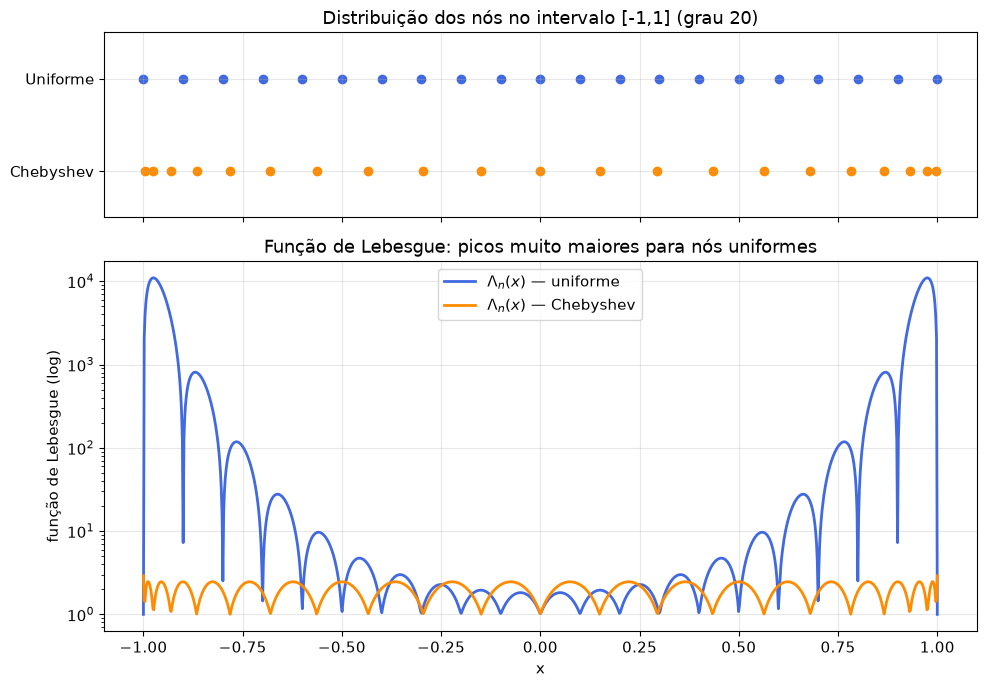

Pico da função de Lebesgue (grau 20):
  Nós uniformes:  1.098e+04
  Nós Chebyshev:  2.901e+00


In [12]:
def funcao_lebesgue(x_nos, x):
    """Calcula a função de Lebesgue Lambda_n(x) = soma_i |L_i(x)| para um conjunto de nós."""
    x = np.asarray(x, dtype=float)
    soma = np.zeros_like(x)
    for i in range(len(x_nos)):
        soma = soma + np.abs(base_lagrange(x_nos, i, x))
    return soma


grau_demo = 20
x_eq_demo = np.linspace(-1, 1, grau_demo + 1)
x_cheb_demo = np.sort(nos_chebyshev(grau_demo))

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                          gridspec_kw={'height_ratios': [1, 2]})

# --- Painel superior: posição dos nós no eixo x (mostra a concentração nas bordas) ---
axs[0].scatter(x_eq_demo, np.ones_like(x_eq_demo), color=COR_POLINOMIO, label='igualmente espaçados')
axs[0].scatter(x_cheb_demo, np.zeros_like(x_cheb_demo), color=COR_NEWTON, label='Chebyshev')
axs[0].set_yticks([0, 1])
axs[0].set_yticklabels(['Chebyshev', 'Uniforme'])
axs[0].set_title(f'Distribuição dos nós no intervalo [-1,1] (grau {grau_demo})')
axs[0].set_ylim(-0.5, 1.5)

# --- Painel inferior: função de Lebesgue para cada conjunto de nós ---
x_fino = np.linspace(-1, 1, 1000)
lambda_eq = funcao_lebesgue(x_eq_demo, x_fino)
lambda_cheb = funcao_lebesgue(x_cheb_demo, x_fino)
axs[1].semilogy(x_fino, lambda_eq, color=COR_POLINOMIO, linewidth=2, label='$\\Lambda_n(x)$ — uniforme')
axs[1].semilogy(x_fino, lambda_cheb, color=COR_NEWTON, linewidth=2, label='$\\Lambda_n(x)$ — Chebyshev')
axs[1].set_xlabel('x')
axs[1].set_ylabel('função de Lebesgue (log)')
axs[1].set_title('Função de Lebesgue: picos muito maiores para nós uniformes')
axs[1].legend()

plt.tight_layout()
plt.show()

print(f'Pico da função de Lebesgue (grau {grau_demo}):')
print(f'  Nós uniformes:  {lambda_eq.max():.3e}')
print(f'  Nós Chebyshev:  {lambda_cheb.max():.3e}')

## Resumo

- O polinômio interpolador de grau $\le n$ para $n+1$ pontos **existe e é único** — Lagrange e Newton apenas o calculam de formas diferentes.
- **Lagrange** é conceitualmente simples e direto, mas precisa ser recalculado inteiro ao adicionar pontos.
- **Newton** (diferenças divididas) constrói o polinômio **incrementalmente**, sendo mais eficiente quando novos pontos são adicionados.
- O **erro de truncamento** $E_n(x)$ depende do produto $(x-x_0)\cdots(x-x_n)$ e da derivada de ordem $n+1$ de $f$.
- Nós **igualmente espaçados** podem causar o **fenômeno de Runge**: o erro explode nas bordas ao aumentar o grau, mesmo para funções suaves.
- Nós de **Chebyshev**, concentrados nas extremidades, resolvem esse problema e garantem convergência estável — por isso são a escolha recomendada ao interpolar com grau alto.